# 23. Bundles, Gauges, and Gauge-Equivariant Convolution

**Primary:** Bronstein, Bruna, Cohen & Veličković, *Geometric Deep Learning*, §4.5, pp. 56–61, [arXiv:2104.13478](https://arxiv.org/abs/2104.13478).

**Supplementary:** Borde & Bronstein, *Mathematical Foundations of Geometric Deep Learning*, especially the orange box on printed p. 49, [arXiv:2508.02723](https://arxiv.org/abs/2508.02723); Loring W. Tu's differential geometry texts; Gerken et al., *Geometric Deep Learning and Equivariant Neural Networks*.

**Learning goals:** Define vector bundles and local frames; derive gauge transformation laws; construct pointwise intertwiners and gauge-equivariant convolutions; understand the role of parallel transport and connections in geometric signal processing.


## 1. Why bundles?

A scalar signal $f:\mathcal M\to\mathbb R$ takes values in a fixed space. A tangent vector field $X$ satisfies $X(u)\in T_u\mathcal M$. Although $T_u\mathcal M$ and $T_v\mathcal M$ have equal dimension, they are distinct spaces and there is no canonical way to add their vectors.

A **rank-$d$ vector bundle** is a smooth map $\pi:E\to\mathcal M$ with vector-space fibres $E_u=\pi^{-1}(u)\cong\mathbb R^d$, locally isomorphic to a product $U\times\mathbb R^d$.

**Example:** the tangent bundle $T\mathcal M$.

A **section** $X:\mathcal M\to E$ obeys $\pi\circ X=\mathrm{id}_{\mathcal M}$ and is the geometric notion of a field.


## 2. Local trivializations, transition functions, and topology

A local trivialization identifies $\pi^{-1}(U)$ with $U\times\mathbb R^d$. On overlapping patches, the corresponding frames differ by transition functions $g_{ab}:U_a\cap U_b\to\mathrm{GL}(d,\mathbb R)$ satisfying $g_{ac}=g_{ab}g_{bc}$ on triple overlaps.

A bundle can be locally trivial but globally twisted. The Möbius line bundle is a classic example; $TS^2$ is not globally trivial, whereas $TS^1$ is.

A local frame (or gauge, see below) $\omega_u:\mathbb R^d\to E_u$ expresses a geometric section as $X(u)=\omega_u x(u)$. The coordinate function $x$ depends on the frame; $X$ does not.

A **principal frame bundle** organizes all allowed frames, and a local gauge is a local section of this principal bundle. Associated vector bundles $P\times_\rho V$ describe fields transforming under a representation $\rho$.


### Definition: Gauge

Let $\pi:E\to M$ be a smooth vector bundle of rank $d$ over a smooth manifold $M$.

A **gauge** on an open subset $U\subseteq M$ is a smooth choice of a basis for each fibre $E_u$, where $u\in U$.

Equivalently, a gauge is a smooth family of linear isomorphisms

$$
\boxed{
\omega_u:\mathbb R^d\longrightarrow E_u,
\qquad u\in U.
}
$$

Thus, a gauge allows us to represent geometric objects in the fibres using coordinates in $\mathbb R^d$.

If $X$ is a section of $E$, then relative to a gauge $\omega$, we can write

$$
X(u)=\omega_u x(u),
$$

where $x(u)\in\mathbb R^d$ is the coordinate representation of $X(u)$.

**Example: Tangent bundle**

Consider the tangent bundle $TM$ of a two-dimensional Riemannian manifold $M$.

A local gauge consists of choosing two smoothly varying, linearly independent tangent vectors

$$
e_1(u),e_2(u)\in T_uM
$$

at every point $u$ in some open subset $U\subseteq M$.

A tangent vector field $X$ can then be expressed as

$$
X(u)=x^1(u)e_1(u)+x^2(u)e_2(u).
$$

The coefficients $x^1(u)$ and $x^2(u)$ depend on the chosen gauge, but the geometric vector $X(u)$ does not.

### Gauge Transformations

Suppose $\omega$ and $\omega'$ are two gauges on the same open subset $U$.

They are related by a smooth map

$$
g:U\longrightarrow G,
$$

where $G$ is the structure group of the bundle.

The new gauge is

$$
\boxed{
\omega'_u=\omega_u g(u).
}
$$

The map $g$ is called a **gauge transformation**.

Since the underlying geometric field must remain unchanged,

$$
\omega_u x(u)=\omega'_u x'(u).
$$

Consequently,

$$
\boxed{
x'(u)=g(u)^{-1}x(u).
}
$$

Here we use the standard representation of $G$ on $\mathbb R^d$.

**Remark:** A gauge is a choice of local frame, whereas a gauge transformation changes that choice. Gauge transformations do not change the underlying geometric field; they change only its coordinate representation.

In geometric deep learning, **gauge equivariance** ensures that a neural network's output transforms consistently when the local frames used to represent its input features are changed.

## 3. Structure groups and gauge transformations

The **structure group** specifies allowed frame changes: $\mathrm{GL}(d)$ for arbitrary frames, $\mathrm O(d)$ for orthonormal frames, and $\mathrm{SO}(d)$ for oriented orthonormal frames.

Following the proto-book, let $\omega'_u=\omega_u g_u$. Since $X$ must remain unchanged,

$$\boxed{x'(u)=\rho(g_u^{-1})x(u).}$$

For the standard representation, $\omega'_u x'(u)=\omega_u g_ug_u^{-1}x(u)=X(u)$.

A gauge change is a *passive* change of local coordinates, potentially different at every point. It does not move the base point. This distinguishes gauge symmetry from a global spatial rotation of a whole object.


## 4. Computational example: changing a frame

**What the code demonstrates:** coordinates change under a rotated basis, but the geometric vector stays fixed.

Original: [1.4 0.6]
New coordinates: [ 1.40580305 -0.5862745 ]
Reconstruction error: 1.1102230246251565e-16


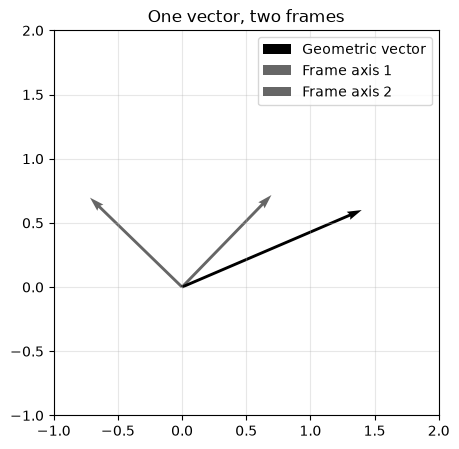

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define a geometric vector and a rotated frame.
X = np.array([1.4, 0.6])
a = 0.8
R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])

# Change coordinates using the inverse frame rotation.
x_prime = R.T @ X

# Reconstruct the same geometric vector.
print("Original:", X)
print("New coordinates:", x_prime)
print("Reconstruction error:", np.linalg.norm(R @ x_prime - X))

# Visualize the vector and rotated frame axes.
fig, ax = plt.subplots(figsize=(5, 5))
ax.quiver(0, 0, *X, angles="xy", scale_units="xy", scale=1, label="Geometric vector")
for j in range(2):
    ax.quiver(0, 0, *R[:, j], angles="xy", scale_units="xy", scale=1, alpha=0.6, label=f"Frame axis {j+1}")
ax.set(xlim=(-1, 2), ylim=(-1, 2), aspect="equal", title="One vector, two frames")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 5. Gauge-equivariant pointwise layers

Suppose input and output fibres carry representations $\rho_{\mathrm{in}}$ and $\rho_{\mathrm{out}}$ of $G$. A linear layer $W$ is an **intertwiner** if

$$\boxed{W\rho_{\mathrm{in}}(g)=\rho_{\mathrm{out}}(g)W\quad\forall g\in G.}$$

The coordinate expression of a general layer changes when frames change; an intertwiner respects those changes automatically.

The proto-book illustrates this using RGB pixels as rank-3 fibres and permutations of channel bases as gauge transformations. This is a conceptual model of basis freedom, not a claim that all RGB permutations are useful physical symmetries.

For the standard representation of $\mathrm{SO}(2)$, matrices commuting with every rotation are $W=aI+bJ$, where $J$ is rotation by $90^\circ$. If reflections are included, the commutant reduces to scalar multiples of the identity.


## 6. Computational example: an intertwiner

**What the code demonstrates:** an $\mathrm{SO}(2)$-equivariant matrix commutes with rotation; a generic matrix need not.

In [2]:
import numpy as np

# Define a rotation and the 90-degree rotation matrix.
a = 1.13
R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
J = np.array([[0., -1.], [1., 0.]])

# Compare constrained and unconstrained linear layers.
W_good = 0.8*np.eye(2) + 0.35*J
W_bad = np.array([[1., 2.], [-0.4, 0.7]])
x = np.array([0.3, -1.1])

# Measure W(Rx) - R(Wx).
for name, W in [("Intertwiner", W_good), ("Generic", W_bad)]:
    print(name, np.linalg.norm(W @ (R @ x) - R @ (W @ x)))

Intertwiner 1.1443916996305594e-16
Generic 1.6786533446733929


## 7. Scalar convolution versus vector-valued convolution

For a scalar field, a general kernel operator is

$$y(u)=\int_{\mathcal M}\theta(u,v)x(v)\,dV(v).$$

Scalars transform trivially under frame changes, so this operator is gauge invariant. But gauge symmetry alone **does not imply weight sharing**: $\theta(u,v)$ may vary arbitrarily with both points.

For vector fields, the naive formula $y(u)=\int\Theta(u,v)x(v)\,dV(v)$ is not intrinsically meaningful unless the kernel identifies the input fibre $E_v$ with the output fibre $E_u$. Independent gauge changes at $u$ and $v$ make a fixed, untransported matrix kernel excessively constrained.


## 8. Connections and parallel transport

A **connection** provides covariant differentiation and transport along paths. For a curve $\gamma$ from $v$ to $u$ it determines a linear map

$$P_{v\to u}^{\gamma}:E_v\longrightarrow E_u.$$

For tangent vectors, the Levi-Civita connection preserves the Riemannian metric. On curved manifolds, parallel transport can depend on the path (holonomy). The proto-book assumes a locally unique geodesic, so the convolution kernel is supported in a sufficiently small neighbourhood.

Under local frame changes $\omega'_u=\omega_u g_u$,

$$\boxed{P'_{v\to u}=g_u^{-1}P_{v\to u}g_v.}$$

This is the crucial transformation law that allows signals in different fibres to be compared consistently.


## 9. Gauge-equivariant convolution: the main construction

Transport the feature from $v$ to the output fibre at $u$, filter it there, and aggregate:

$$\boxed{y(u)=\int_{\mathcal M}\Theta(u,v)P_{v\to u}x(v)\,dV(v).}$$

This is the central construction of §4.5 (equation (23) of the proto-book).

### Derivation

Under the passive gauge convention,

$$x'(v)=g_v^{-1}x(v),\qquad P'_{v\to u}=g_u^{-1}P_{v\to u}g_v.$$

Assume the kernel commutes with the output structure-group action: $\Theta(u,v)g_u=g_u\Theta(u,v)$. Then

$$
\begin{aligned}
y'(u)
&=\int\Theta(u,v)P'_{v\to u}x'(v)\,dV(v)\\
&=\int\Theta(u,v)g_u^{-1}P_{v\to u}g_vg_v^{-1}x(v)\,dV(v)\\
&=g_u^{-1}y(u).
\end{aligned}
$$

Thus the operator is gauge equivariant: the geometric output does not depend on arbitrary frame choices.

For different input and output representations, the kernel satisfies the appropriate **intertwiner** condition rather than simply commuting with a single representation.


## 10. Signal-processing interpretation

The operator is a geometrically corrected convolution:

1. **Transport:** express a neighbour's feature in the output fibre.
2. **Filter:** apply a kernel compatible with the local representation.
3. **Aggregate:** integrate or sum the transported messages.

Ordinary grid convolution uses translations to compare nearby samples. A manifold generally has no global translation group; a connection instead supplies a local comparison rule.

**Isotropy and anisotropy:** a scalar kernel acting on standard vector features is strongly constrained by gauge symmetry. Direction-sensitive filters are still possible, but require kernels and feature representations with the correct transformation laws. Gauge equivariance is not synonymous with isotropy.

**Holonomy:** transporting around a loop may rotate a vector. This effect reflects curvature and matters for orientation-sensitive geometric signals.


## 11. Discrete gauge-equivariant message passing

On a mesh or graph, a connection-aware analogue is

$$y_i=\sum_{j\in\mathcal N(i)}w_{ij}P_{j\to i}x_j.$$

Here $w_{ij}$ is a gauge-invariant scalar weight and $P_{j\to i}$ is a discrete transporter. The layer is equivariant if $P'_{j\to i}=g_i^{-1}P_{j\to i}g_j$.

**What the code demonstrates:** independently rotate every vertex frame and check that the aggregated output changes only by the inverse rotation at its destination. This is an algebraic test, not a numerical implementation of Levi-Civita transport on a curved mesh.


In [3]:
import numpy as np

# Create a small cycle graph with two-dimensional node features.
rng = np.random.default_rng(12)
n = 4
x = rng.normal(size=(n, 2))
edges = [(0, 1), (1, 2), (2, 3), (3, 0)]

# Define identity transport in a reference gauge.
P = {}
for i, j in edges:
    P[(i, j)] = np.eye(2)
    P[(j, i)] = np.eye(2)

# Aggregate transported messages.
def aggregate(features, transport):
    out = np.zeros_like(features)
    for (i, j), matrix in transport.items():
        out[i] += matrix @ features[j]
    return out

y = aggregate(x, P)

# Choose an independent frame rotation at each vertex.
angles = rng.uniform(-np.pi, np.pi, n)
G = [np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]]) for a in angles]

# Transform both feature coordinates and transport matrices.
x_prime = np.array([G[i].T @ x[i] for i in range(n)])
P_prime = {(i, j): G[i].T @ matrix @ G[j] for (i, j), matrix in P.items()}

# Verify gauge equivariance.
y_prime = aggregate(x_prime, P_prime)
expected = np.array([G[i].T @ y[i] for i in range(n)])
print("Maximum equivariance error:", np.max(np.abs(y_prime - expected)))
assert np.allclose(y_prime, expected)

Maximum equivariance error: 4.440892098500626e-16


## 12. Relation to gauge theory in physics

In a local trivialization, a connection can be expressed as $D=d+A$, where $A$ is a matrix-valued one-form. With the convention $x'=g^{-1}x$,

$$\boxed{A'=g^{-1}Ag+g^{-1}dg},$$

which ensures $D'x'=g^{-1}Dx$. The curvature is

$$F=dA+A\wedge A,\qquad F'=g^{-1}Fg.$$

Gauge-equivariant neural networks use the same mathematical requirement of independence from local frame choices. They do not necessarily introduce a *dynamical* gauge field or impose physical field equations. A connection may be fixed by geometry, estimated, or learned, depending on the architecture.


## 13. Connection with geometric deep learning

This section expands the orange box **“Manifolds in Geometric Deep Learning”** on printed p. 49 of Borde & Bronstein's *Mathematical Foundations of Geometric Deep Learning*. The box emphasizes that manifold learning should respect intrinsic geometric structure, including distances, geodesics, curvature, and local charts, rather than assume a regular grid. It specifically motivates convolution-like operations built from geometrically defined neighbourhoods.

The gauge-theoretic refinement is:

- **Manifold:** the domain and its neighbourhood geometry.
- **Vector bundle:** the type of feature attached to each point.
- **Connection:** the rule for comparing features at different points.
- **Structure group and representations:** the allowed changes of local coordinates.
- **Gauge-equivariant kernel:** a learnable operator whose geometric meaning is independent of those changes.

This yields the pipeline

$$x(v)\xrightarrow{P_{v\to u}}P_{v\to u}x(v)
\xrightarrow{\Theta(u,v)}\text{filtered message}
\xrightarrow{\int/\sum}y(u).$$

**What gauge symmetry does not guarantee:** spatial weight sharing, locality, or stability under arbitrary geometric perturbations. These require further geometric assumptions, kernel parameterizations, or regularization.

**Connection to GNNs:** transport-aware message passing generalizes neighbourhood aggregation to fibre-valued signals. **Connection to CNNs:** constrained local kernels recover a form of convolution without a global translation group. **Connection to physics:** covariant differentiation and parallel transport make comparisons of locally represented fields meaningful.

The manifold hypothesis (discussed just after the orange box) motivates low-dimensional geometry in data, but does not guarantee that real datasets form smooth manifolds or possess a known connection.

**Conclusion:** gauge theory provides the language and mathematical constraints for constructing convolution-like operators on locally oriented geometric signals without depending on arbitrary frame choices.


## 14. Exercises

1. Give an example and a non-example of a globally trivial vector bundle.
2. Prove $X=\omega x=\omega'x'$ for $\omega'=\omega g$ and $x'=g^{-1}x$.
3. Derive the cocycle condition for transition functions on triple overlaps.
4. Show that $aI+bJ$ commutes with every planar rotation.
5. Explain why an arbitrary matrix-valued kernel between fibres is not automatically gauge equivariant.
6. Derive $P'_{v\to u}=g_u^{-1}P_{v\to u}g_v$.
7. Reproduce the gauge-equivariance calculation for transported convolution.
8. Change the graph and transporters in the code; verify equivariance.
9. Derive the transformation law for $A$ from $D'x'=g^{-1}Dx$.
10. Propose a directional kernel on a mesh that transforms consistently under $\mathrm{SO}(2)$ frame rotations.


## References

1. Bronstein, M. M., Bruna, J., Cohen, T., and Veličković, P., *Geometric Deep Learning: Grids, Groups, Graphs, Geodesics, and Gauges*, §4.5, printed pp. 56–61. https://arxiv.org/abs/2104.13478
2. Borde, A., and Bronstein, M., *Mathematical Foundations of Geometric Deep Learning*, orange box “Manifolds in Geometric Deep Learning,” printed p. 49. https://arxiv.org/abs/2508.02723
3. Tu, L. W., *An Introduction to Manifolds*. Springer.
4. Tu, L. W., *Differential Geometry: Connections, Curvature, and Characteristic Classes*. Springer.
5. Gerken, J. E., et al., *Geometric Deep Learning and Equivariant Neural Networks*. https://arxiv.org/abs/2105.13926

The notebook's bundle background and physics comparison expand beyond the proto-book; its central convolution construction follows §4.5.
